# 3.2.4. Phân tích khám phá dữ liệu ban đầu

Cài thư viện và tải dữ liệu

In [2]:
# Khai báo thư viện
from pathlib import Path
from IPython.display import display
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown

# Cấu hình hiển thị
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)

# Kiểm tra môi trường
print('Python:', sys.executable)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('gdown:', gdown.__version__)

# Kiểm tra Python kernel đang sử dụng
print('Python đang chạy:', sys.executable)

# Link thư mục dữ liệu Olist trên Google Drive
DRIVE_FOLDER_URL = 'https://drive.google.com/drive/folders/1X0smlok_stVNIQL5dB0R4SKthEwDOUNG?usp=drive_link'

# Xác định thư mục gốc của project
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / 'data').exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / 'data').exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        'Không tìm thấy thư mục data của project.'
    )

# Khai báo thư mục dữ liệu và thư mục lưu kết quả EDA
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
OUTPUT_DIR = PROJECT_ROOT / 'notebooks' / 'eda_output'

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Kiểm tra dữ liệu hiện có
csv_files = sorted(DATA_DIR.rglob('*.csv'))

# Chỉ tải dữ liệu khi chưa đủ 9 file CSV
if len(csv_files) < 9:
    print('Chưa đủ dữ liệu. Đang tải từ Google Drive...')

    gdown.download_folder(
        url=DRIVE_FOLDER_URL,
        output=str(DATA_DIR),
        quiet=False,
        use_cookies=False
    )

    csv_files = sorted(DATA_DIR.rglob('*.csv'))

else:
    print('Dữ liệu đã có trong data/raw. Không cần tải lại.')

# Tạo dictionary đường dẫn file
CSV_PATHS = {
    file.name: file
    for file in csv_files
}

# Kiểm tra kết quả
print('\nProject root:', PROJECT_ROOT)
print('Data directory:', DATA_DIR)
print(f'Tìm thấy {len(csv_files)} file CSV:')

for file in csv_files:
    print(' -', file.name)

Python: c:\Users\Admin\AppData\Local\Python\pythoncore-3.11-64\python.exe
NumPy: 2.4.6
Pandas: 3.0.6
gdown: 6.4.2
Python đang chạy: c:\Users\Admin\AppData\Local\Python\pythoncore-3.11-64\python.exe
Dữ liệu đã có trong data/raw. Không cần tải lại.

Project root: c:\Users\Admin\Downloads\olist-bidss-group08
Data directory: c:\Users\Admin\Downloads\olist-bidss-group08\data\raw
Tìm thấy 9 file CSV:
 - olist_customers_dataset.csv
 - olist_geolocation_dataset.csv
 - olist_order_items_dataset.csv
 - olist_order_payments_dataset.csv
 - olist_order_reviews_dataset.csv
 - olist_orders_dataset.csv
 - olist_products_dataset.csv
 - olist_sellers_dataset.csv
 - product_category_name_translation.csv


In [3]:
# Đọc các file CSV
customers = pd.read_csv(CSV_PATHS['olist_customers_dataset.csv'])
geolocation = pd.read_csv(CSV_PATHS['olist_geolocation_dataset.csv'])
order_items = pd.read_csv(CSV_PATHS['olist_order_items_dataset.csv'])
payments = pd.read_csv(CSV_PATHS['olist_order_payments_dataset.csv'])
reviews = pd.read_csv(CSV_PATHS['olist_order_reviews_dataset.csv'])
orders = pd.read_csv(CSV_PATHS['olist_orders_dataset.csv'])
products = pd.read_csv(CSV_PATHS['olist_products_dataset.csv'])
sellers = pd.read_csv(CSV_PATHS['olist_sellers_dataset.csv'])
category_translation = pd.read_csv(
    CSV_PATHS['product_category_name_translation.csv']
)

# Gom các bảng để kiểm tra
tables = {
    'Customers': customers,
    'Geolocation': geolocation,
    'OrderItems': order_items,
    'Payments': payments,
    'Reviews': reviews,
    'Orders': orders,
    'Products': products,
    'Sellers': sellers,
    'CategoryTranslation': category_translation
}

# Tổng hợp số dòng và số cột
summary = pd.DataFrame({
    'Table': tables.keys(),
    'Rows': [len(df) for df in tables.values()],
    'Columns': [len(df.columns) for df in tables.values()]
})

# Hiển thị kết quả
display(summary)

,Table,Rows,Columns
0,Customers,99441,5
1,Geolocation,1000163,5
2,OrderItems,112650,7
3,Payments,103886,5
4,Reviews,99224,7
5,Orders,99441,8
6,Products,32951,9
7,Sellers,3095,4
8,CategoryTranslation,71,2


Chuẩn bị dữ liệu dùng chung cho EDA

In [4]:
# Chuyển các cột thời gian của Orders sang datetime
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    orders[col] = pd.to_datetime(
        orders[col],
        errors='coerce'
    )

# Chuyển các cột thời gian của Reviews sang datetime
reviews['review_creation_date'] = pd.to_datetime(
    reviews['review_creation_date'],
    errors='coerce'
)

reviews['review_answer_timestamp'] = pd.to_datetime(
    reviews['review_answer_timestamp'],
    errors='coerce'
)

# Chọn review trả lời sau cùng của mỗi đơn
reviews_latest = (
    reviews
    .sort_values(
        ['order_id', 'review_answer_timestamp', 'review_id'],
        na_position='first'
    )
    .drop_duplicates(
        subset='order_id',
        keep='last'
    )
)

# Lấy các đơn đã giao và có đủ ngày giao thực tế, ngày giao dự kiến
delivery = orders[
    (orders['order_status'] == 'delivered') &
    orders['order_delivered_customer_date'].notna() &
    orders['order_estimated_delivery_date'].notna()
].copy()

# Tính số ngày giao trễ
delivery['delay_days_raw'] = (
    delivery['order_delivered_customer_date'].dt.normalize()
    - delivery['order_estimated_delivery_date'].dt.normalize()
).dt.days

# Đơn không trễ được gán delay_days = 0
delivery['delay_days'] = (
    delivery['delay_days_raw']
    .clip(lower=0)
)

# Phân loại tình trạng giao hàng
delivery['delivery_status'] = np.where(
    delivery['delay_days'] > 0,
    'Giao trễ',
    'Đúng hạn'
)

# Ghép Review Score vào dữ liệu giao hàng
delivery_review = delivery.merge(
    reviews_latest[['order_id', 'review_score']],
    on='order_id',
    how='left'
)

# Kiểm tra dữ liệu sau khi xử lý
print('Số đơn đã giao dùng cho phân tích:', len(delivery))
print('Số review mới nhất theo đơn:', len(reviews_latest))
print(
    'Số đơn giao hàng có review:',
    delivery_review['review_score'].notna().sum()
)

Số đơn đã giao dùng cho phân tích: 96470
Số review mới nhất theo đơn: 98673
Số đơn giao hàng có review: 95824


## 3.2.4.1. Phân bố trạng thái đơn hàng

,order_status,order_count,percentage
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


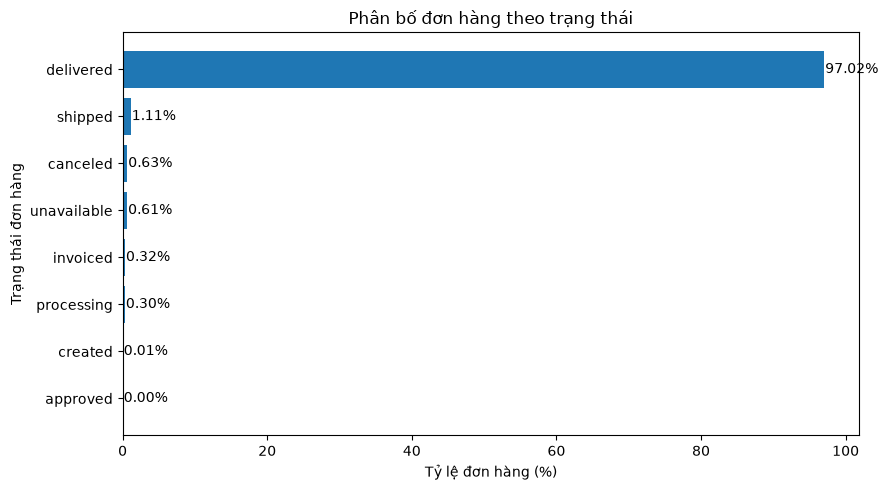

In [5]:
# Tổng hợp số đơn theo trạng thái
status_summary = (
    orders['order_status']
    .value_counts()
    .rename_axis('order_status')
    .reset_index(name='order_count')
)

# Tính tỷ lệ phần trăm
status_summary['percentage'] = (
    status_summary['order_count']
    / status_summary['order_count'].sum()
    * 100
)

# Hiển thị bảng kết quả
display(status_summary)

# Sắp xếp dữ liệu để vẽ biểu đồ
plot_data = status_summary.sort_values(
    'percentage',
    ascending=True
)

# Vẽ biểu đồ
plt.figure(figsize=(9, 5))

bars = plt.barh(
    plot_data['order_status'],
    plot_data['percentage']
)

# Hiển thị tỷ lệ trên từng thanh
for bar, value in zip(
    bars,
    plot_data['percentage']
):
    plt.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.2f}%',
        va='center'
    )

plt.title('Phân bố đơn hàng theo trạng thái')
plt.xlabel('Tỷ lệ đơn hàng (%)')
plt.ylabel('Trạng thái đơn hàng')
plt.tight_layout()

# Lưu và hiển thị biểu đồ
plt.savefig(
    OUTPUT_DIR / '01_order_status.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 3.2.4.2. Xu hướng số lượng đơn hàng theo thời gian

,order_purchase_timestamp,order_count
4,2017-01-01,800
5,2017-02-01,1780
6,2017-03-01,2682
7,2017-04-01,2404
8,2017-05-01,3700
9,2017-06-01,3245
10,2017-07-01,4026
11,2017-08-01,4331
12,2017-09-01,4285
13,2017-10-01,4631


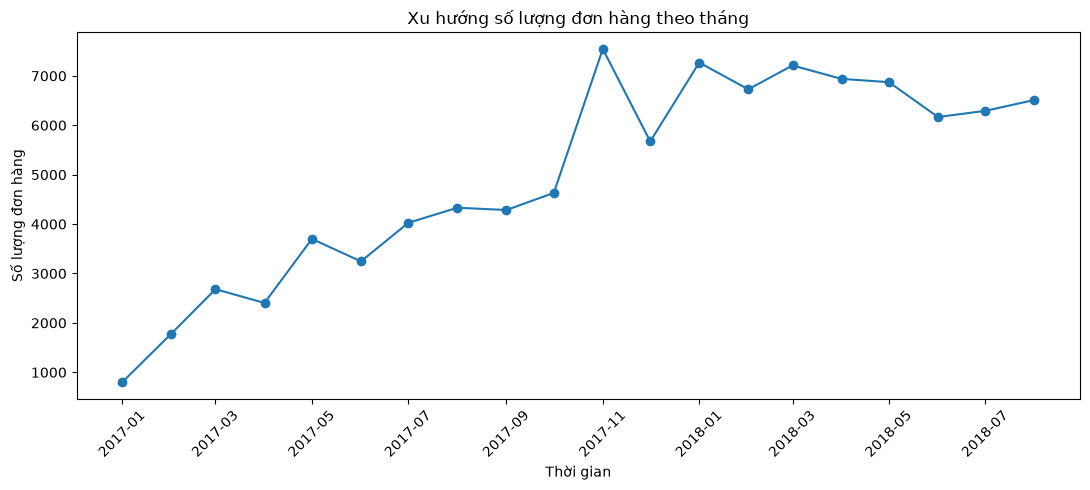

In [6]:
# Tổng hợp số lượng đơn hàng theo tháng
monthly_orders = (
    orders
    .dropna(subset=['order_purchase_timestamp'])
    .set_index('order_purchase_timestamp')
    .resample('MS')['order_id']
    .nunique()
    .reset_index(name='order_count')
)

# Lọc giai đoạn có dữ liệu tương đối đầy đủ
monthly_plot = monthly_orders[
    (monthly_orders['order_purchase_timestamp'] >= '2017-01-01') &
    (monthly_orders['order_purchase_timestamp'] <= '2018-08-01')
].copy()

# Hiển thị bảng kết quả
display(monthly_plot)

# Vẽ biểu đồ xu hướng
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_plot['order_purchase_timestamp'],
    monthly_plot['order_count'],
    marker='o'
)

plt.title('Xu hướng số lượng đơn hàng theo tháng')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng đơn hàng')
plt.xticks(rotation=45)
plt.tight_layout()

# Lưu và hiển thị biểu đồ
plt.savefig(
    OUTPUT_DIR / '02_monthly_orders.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 3.2.4.3. Tình trạng giao đúng hạn và giao trễ

,delivery_status,order_count,percentage
0,Đúng hạn,89936,93.22691
1,Giao trễ,6534,6.77309


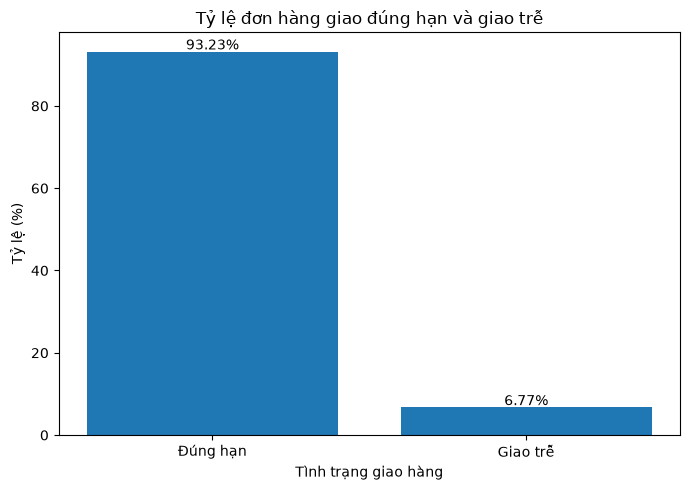

In [7]:
# Tổng hợp số đơn theo tình trạng giao hàng
delivery_summary = (
    delivery['delivery_status']
    .value_counts()
    .rename_axis('delivery_status')
    .reset_index(name='order_count')
)

# Tính tỷ lệ phần trăm
delivery_summary['percentage'] = (
    delivery_summary['order_count']
    / delivery_summary['order_count'].sum()
    * 100
)

# Hiển thị bảng kết quả
display(delivery_summary)

# Vẽ biểu đồ
plt.figure(figsize=(7, 5))

bars = plt.bar(
    delivery_summary['delivery_status'],
    delivery_summary['percentage']
)

# Hiển thị tỷ lệ trên cột
for bar, value in zip(
    bars,
    delivery_summary['percentage']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{value:.2f}%',
        ha='center'
    )

plt.title('Tỷ lệ đơn hàng giao đúng hạn và giao trễ')
plt.xlabel('Tình trạng giao hàng')
plt.ylabel('Tỷ lệ (%)')
plt.tight_layout()

# Lưu và hiển thị biểu đồ
plt.savefig(
    OUTPUT_DIR / '03_delivery_status.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 3.2.4.4. Phân bố điểm đánh giá của khách hàng

,review_score,review_count,percentage
0,1,11363,11.515815
1,2,3131,3.173107
2,3,8133,8.242376
3,4,19038,19.294032
4,5,57008,57.774670


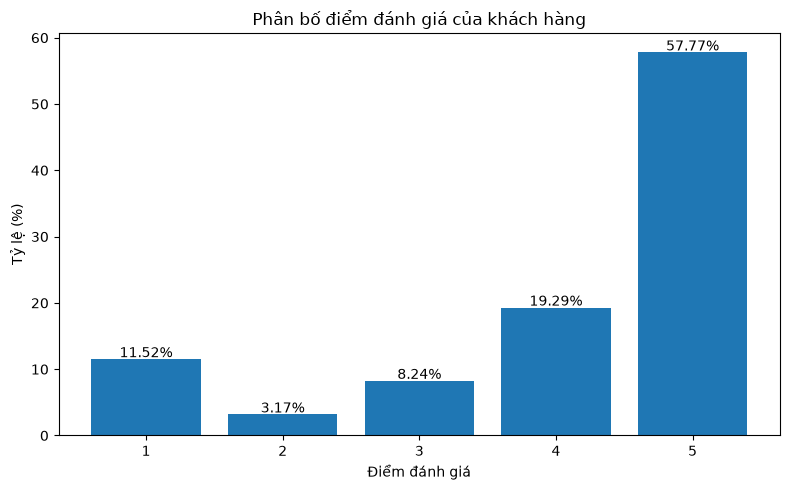

In [8]:
# Tổng hợp số review theo từng mức điểm
review_summary = (
    reviews_latest['review_score']
    .value_counts()
    .sort_index()
    .rename_axis('review_score')
    .reset_index(name='review_count')
)

# Tính tỷ lệ phần trăm
review_summary['percentage'] = (
    review_summary['review_count']
    / review_summary['review_count'].sum()
    * 100
)

# Hiển thị bảng kết quả
display(review_summary)

# Vẽ biểu đồ
plt.figure(figsize=(8, 5))

bars = plt.bar(
    review_summary['review_score'].astype(str),
    review_summary['percentage']
)

# Hiển thị tỷ lệ trên cột
for bar, value in zip(
    bars,
    review_summary['percentage']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f'{value:.2f}%',
        ha='center'
    )

plt.title('Phân bố điểm đánh giá của khách hàng')
plt.xlabel('Điểm đánh giá')
plt.ylabel('Tỷ lệ (%)')
plt.tight_layout()

# Lưu và hiển thị biểu đồ
plt.savefig(
    OUTPUT_DIR / '04_review_score.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [9]:
## 3.2.4.5. Mối liên hệ giữa tình trạng giao hàng và điểm đánh giá

In [10]:
# Lọc các đơn có đầy đủ Review Score
review_delivery_valid = (
    delivery_review
    .dropna(subset=['review_score'])
    .copy()
)

# Đánh dấu review thấp từ 1 đến 2 sao
review_delivery_valid['is_low_review'] = (
    review_delivery_valid['review_score'] <= 2
)

# Tổng hợp review theo tình trạng giao hàng
review_delivery_summary = (
    review_delivery_valid
    .groupby('delivery_status')
    .agg(
        order_count=('order_id', 'nunique'),
        average_review=('review_score', 'mean'),
        low_review_rate=('is_low_review', 'mean')
    )
    .reset_index()
)

# Chuyển tỷ lệ review thấp sang phần trăm
review_delivery_summary['low_review_rate'] *= 100

# Làm tròn kết quả
review_delivery_summary['average_review'] = (
    review_delivery_summary['average_review']
    .round(2)
)

review_delivery_summary['low_review_rate'] = (
    review_delivery_summary['low_review_rate']
    .round(2)
)

# Hiển thị kết quả
display(review_delivery_summary)

,delivery_status,order_count,average_review,low_review_rate
0,Giao trễ,6381,2.27,62.42
1,Đúng hạn,89443,4.29,9.27


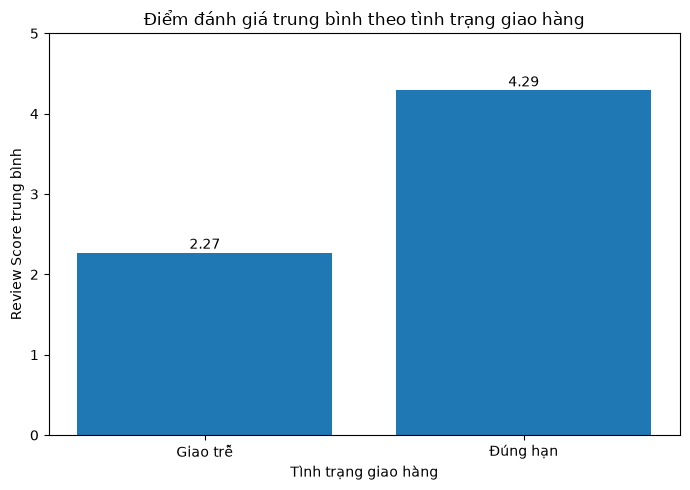

In [11]:
# Chuẩn bị dữ liệu để vẽ biểu đồ
review_avg_plot = review_delivery_summary[
    ['delivery_status', 'average_review']
].copy()

# Vẽ biểu đồ
plt.figure(figsize=(7, 5))

bars = plt.bar(
    review_avg_plot['delivery_status'],
    review_avg_plot['average_review']
)

# Hiển thị giá trị trên cột
for bar, value in zip(
    bars,
    review_avg_plot['average_review']
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{value:.2f}',
        ha='center'
    )

plt.title('Điểm đánh giá trung bình theo tình trạng giao hàng')
plt.xlabel('Tình trạng giao hàng')
plt.ylabel('Review Score trung bình')
plt.ylim(0, 5)
plt.tight_layout()

# Lưu và hiển thị biểu đồ
plt.savefig(
    OUTPUT_DIR / '05_delivery_review.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 3.2.4.6. Tương quan giữa các thuộc tính ở cấp đơn hàng

In [12]:
# Tổng hợp Order Items về cấp đơn hàng
order_item_agg = (
    order_items
    .groupby('order_id')
    .agg(
        gmv=('price', 'sum'),
        freight_total=('freight_value', 'sum'),
        item_count=('order_item_id', 'count'),
        seller_count=('seller_id', 'nunique')
    )
    .reset_index()
)

# Tổng hợp Payment về cấp đơn hàng
payment_agg = (
    payments
    .groupby('order_id')
    .agg(
        payment_value=('payment_value', 'sum')
    )
    .reset_index()
)

# Tạo dữ liệu giao hàng ở cấp đơn hàng
delivery_corr = delivery[
    [
        'order_id',
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'delay_days'
    ]
].copy()

# Tính thời gian giao hàng
delivery_corr['delivery_lead_time'] = (
    delivery_corr['order_delivered_customer_date'].dt.normalize()
    - delivery_corr['order_purchase_timestamp'].dt.normalize()
).dt.days

# Ghép các bảng về cùng grain order_id
order_corr = (
    orders[['order_id']]
    .merge(
        order_item_agg,
        on='order_id',
        how='left'
    )
    .merge(
        payment_agg,
        on='order_id',
        how='left'
    )
    .merge(
        reviews_latest[
            ['order_id', 'review_score']
        ],
        on='order_id',
        how='left'
    )
    .merge(
        delivery_corr[
            [
                'order_id',
                'delivery_lead_time',
                'delay_days'
            ]
        ],
        on='order_id',
        how='left'
    )
)

# Kiểm tra tránh nhân dòng khi ghép
print('Số dòng:', len(order_corr))
print(
    'Số order_id duy nhất:',
    order_corr['order_id'].nunique()
)

Số dòng: 99441
Số order_id duy nhất: 99441


In [13]:
# Chọn các thuộc tính số
corr_cols = [
    'gmv',
    'freight_total',
    'payment_value',
    'item_count',
    'seller_count',
    'delivery_lead_time',
    'delay_days',
    'review_score'
]

# Tính hệ số tương quan Spearman
corr_matrix = (
    order_corr[corr_cols]
    .corr(method='spearman')
)

# Hiển thị bảng tương quan
display(corr_matrix.round(2))

,gmv,freight_total,payment_value,item_count,seller_count,delivery_lead_time,delay_days,review_score
gmv,1.00,0.47,0.99,0.18,0.08,0.10,0.02,-0.03
freight_total,0.47,1.00,0.57,0.38,0.14,0.38,0.05,-0.09
payment_value,0.99,0.57,1.00,0.22,0.10,0.14,0.03,-0.04
item_count,0.18,0.38,0.22,1.00,0.35,-0.03,-0.02,-0.10
seller_count,0.08,0.14,0.10,0.35,1.00,-0.05,-0.03,-0.09
delivery_lead_time,0.10,0.38,0.14,-0.03,-0.05,1.00,0.39,-0.23
delay_days,0.02,0.05,0.03,-0.02,-0.03,0.39,1.00,-0.31
review_score,-0.03,-0.09,-0.04,-0.10,-0.09,-0.23,-0.31,1.00


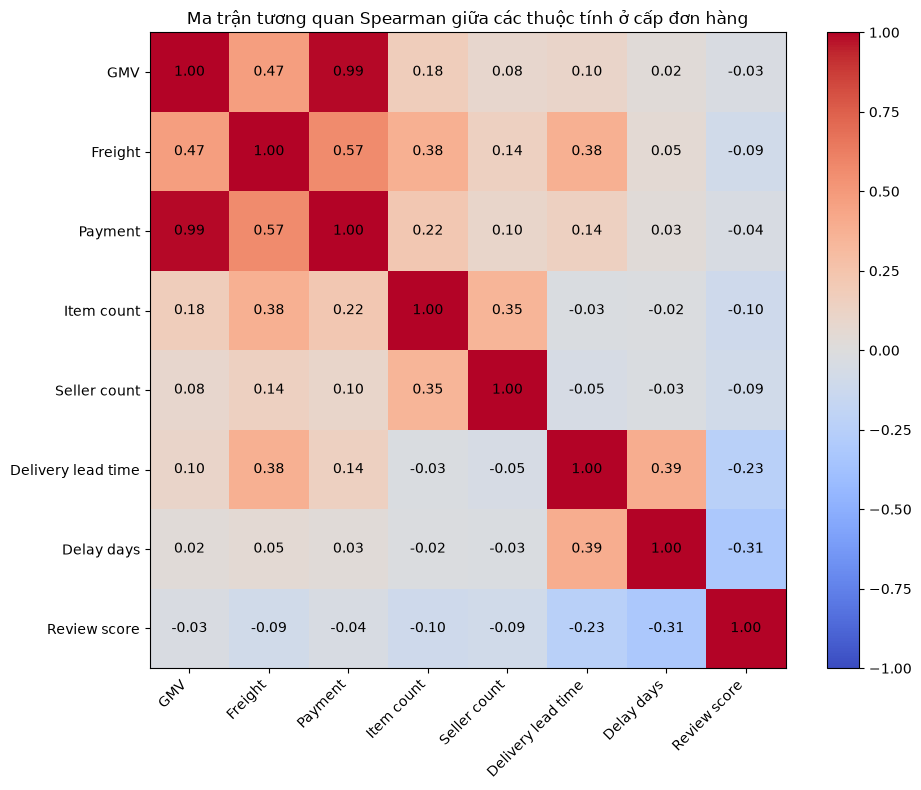

In [14]:
# Tên hiển thị của các thuộc tính
corr_labels = [
    'GMV',
    'Freight',
    'Payment',
    'Item count',
    'Seller count',
    'Delivery lead time',
    'Delay days',
    'Review score'
]

# Vẽ heatmap tương quan
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    corr_matrix,
    vmin=-1,
    vmax=1,
    cmap='coolwarm'
)

# Thiết lập tên thuộc tính trên hai trục
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))

ax.set_xticklabels(
    corr_labels,
    rotation=45,
    ha='right'
)

ax.set_yticklabels(corr_labels)

# Hiển thị hệ số tương quan trong từng ô
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(
            j,
            i,
            f'{corr_matrix.iloc[i, j]:.2f}',
            ha='center',
            va='center'
        )

plt.colorbar(im)
plt.title(
    'Ma trận tương quan Spearman giữa các thuộc tính ở cấp đơn hàng'
)
plt.tight_layout()

# Lưu và hiển thị biểu đồ
plt.savefig(
    OUTPUT_DIR / '06_correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()